In [1]:
import os 
import functions
import mirdata
import librosa
import pandas as pd
import matplotlib.pyplot as plt
import mir_eval
import numpy as np
from tqdm import tqdm

In [2]:
ballroom = mirdata.initialize('ballroom')
# ballroom.download()
# ballroom.validate()
track_ids = ballroom.track_ids

c:\Users\jimea\OneDrive\Documents\QMUL\Sound and Music Computing\Term 2\Music Informatics\venv\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
c:\Users\jimea\OneDrive\Documents\QMUL\Sound and Music Computing\Term 2\Music Informatics\venv\lib\site-packages\google\api_core\_python_version_support.py:275: FutureWarning: You are using a Python version (3.10.11) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [3]:
# Split the prepared dataset into train and test sets (reproducible)
test_size = 0.3
seed = 42

track_ids_shuffled = track_ids.copy()
np.random.seed(seed)
np.random.shuffle(track_ids_shuffled)

split_idx = int(len(track_ids_shuffled) * (1 - test_size))
train_track_ids = track_ids_shuffled[:split_idx]
test_track_ids = track_ids_shuffled[split_idx:]

print(f"Train size: {len(train_track_ids)}")
print(f"Test size: {len(test_track_ids)}")

Train size: 488
Test size: 210


In [4]:
alpha = 400
test_df = pd.DataFrame(columns=["track_name", "track_style", "bpm", "metre", "f1_score"])

for i, track_id in enumerate(tqdm(test_track_ids)):
    track = ballroom.track(track_id)
    split_path = track.audio_path.replace("\\", "/").split("/")
    track_name = split_path[-1]
    track_style = split_path[-2]
    metre = max(track.beats.positions)
    bpm = track.tempo
    estimated_beats, _ = functions.beats_simple(track.audio_path, alpha=alpha, sigma_t=0.9)
    f1_score = mir_eval.beat.f_measure(track.beats.times, estimated_beats)
    test_df.loc[i] = [track_name, track_style, bpm, metre, f1_score]

  0%|          | 0/210 [00:00<?, ?it/s]c:\Users\jimea\OneDrive\Documents\QMUL\Sound and Music Computing\Term 2\Music Informatics\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 210/210 [01:36<00:00,  2.17it/s]


In [5]:
test_df["f1_score"].mean()

np.float64(0.774522854587393)

In [6]:
test_df["f1_score"].idxmax()

np.int64(16)

In [7]:
test_df["f1_score"].idxmin()

np.int64(9)

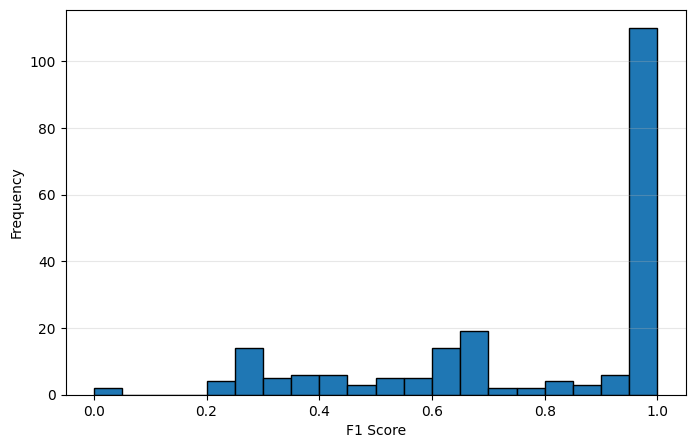

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(test_df["f1_score"], bins=20, edgecolor="black")
plt.xlabel("F1 Score")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

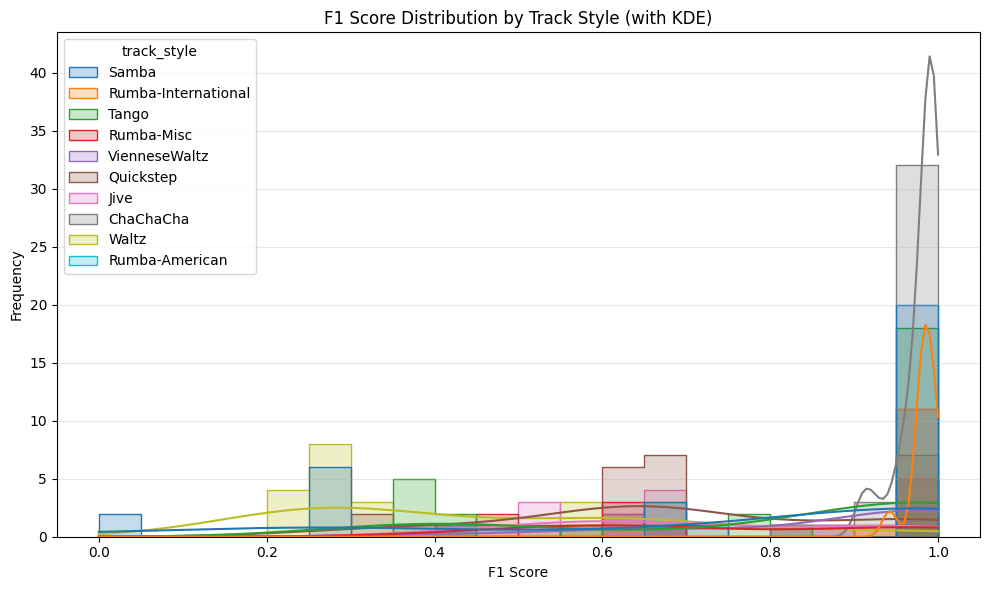

In [9]:
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(
    data=test_df,
    x="f1_score",
    hue="track_style",
    bins=20,
    stat="count",
    element="step",
    common_norm=False,
    kde=True,
)

plt.xlabel("F1 Score")
plt.ylabel("Frequency")
plt.title("F1 Score Distribution by Track Style (with KDE)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
mean_f1_per_style = (
    test_df.groupby("track_style")["f1_score"]
    .mean()
    .sort_values(ascending=False)
)

mean_f1_per_style

track_style
Rumba-American         1.000000
Rumba-International    0.983752
ChaChaCha              0.980167
VienneseWaltz          0.874773
Tango                  0.811673
Samba                  0.755289
Rumba-Misc             0.750545
Jive                   0.726768
Quickstep              0.696813
Waltz                  0.466938
Name: f1_score, dtype: float64

In [11]:
# Count number of samples per class (genre) in the full Ballroom dataset
class_counts = test_df["track_style"].value_counts().sort_values(ascending=False)
class_counts

track_style
ChaChaCha              35
Samba                  32
Waltz                  29
Tango                  29
Quickstep              28
VienneseWaltz          17
Jive                   15
Rumba-International    12
Rumba-Misc             12
Rumba-American          1
Name: count, dtype: int64

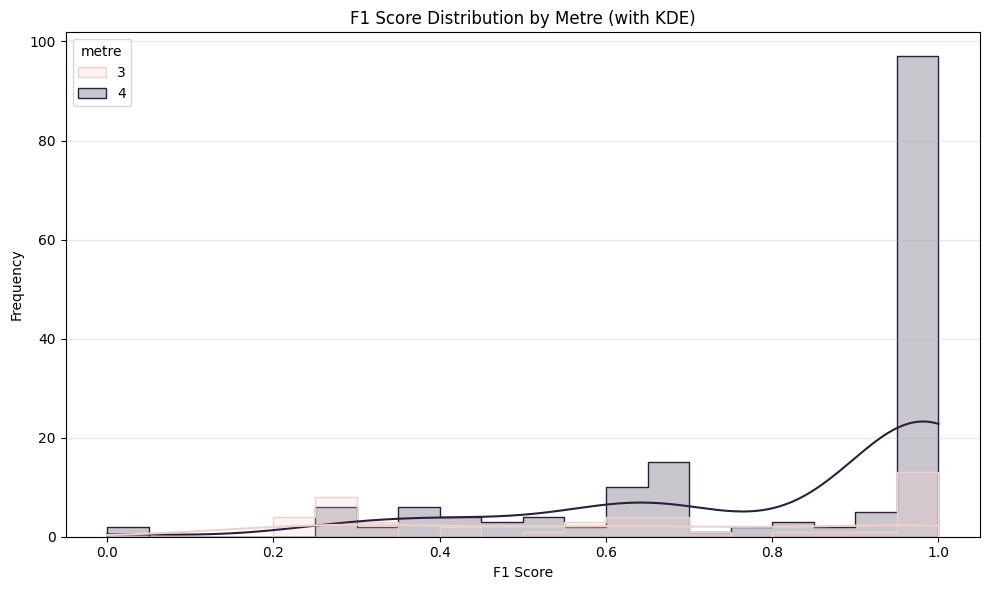

In [12]:
import seaborn as sns

plt.figure(figsize=(10, 6))
plot_df = test_df.dropna(subset=["metre", "f1_score"])
group_sizes = plot_df.groupby("metre").size() if not plot_df.empty else pd.Series(dtype=int)

sns.histplot(
    data=plot_df if not plot_df.empty else test_df,
    x="f1_score",
    hue="metre" if not plot_df.empty else None,
    bins=20,
    stat="count",
    element="step",
    common_norm=False,
    kde=(not group_sizes.empty and group_sizes.min() > 1),
)

plt.xlabel("F1 Score")
plt.ylabel("Frequency")
plt.title("F1 Score Distribution by Metre (with KDE)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Count number of samples per class (metre) in the test set
class_counts = test_df["metre"].value_counts().sort_values(ascending=False)

class_counts

metre
4    164
3     46
Name: count, dtype: int64

In [14]:
mean_f1_per_metre = (
    test_df.groupby("metre")["f1_score"]
    .mean()
    .sort_values(ascending=False)
)

mean_f1_per_metre

metre
4    0.818521
3    0.617660
Name: f1_score, dtype: float64

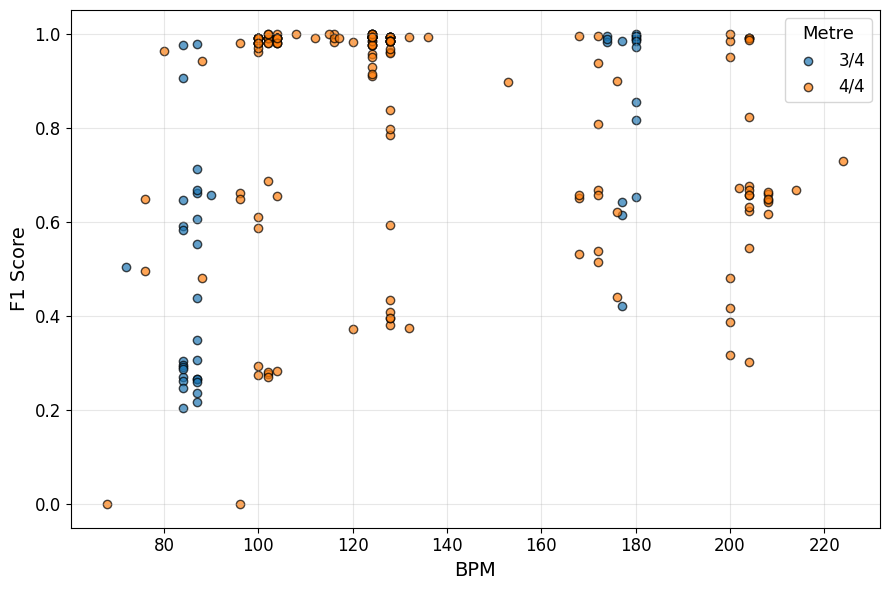

In [15]:
plt.figure(figsize=(9, 6))

for m in sorted(test_df["metre"].unique()):
    mask = test_df["metre"] == m
    plt.scatter(
        test_df.loc[mask, "bpm"],
        test_df.loc[mask, "f1_score"],
        alpha=0.7,
        edgecolor="k",
        label=f"{int(m)}/4",
    )

plt.xlabel("BPM", fontsize=14)
plt.ylabel("F1 Score", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(alpha=0.3)
plt.legend(title="Metre", title_fontsize=13, fontsize=12)
plt.tight_layout()
plt.show()

Input file: ChaChaCha/Albums-Macumba-01.wav
C  FP  FN   F    Err
 61   0   0 1.000 0.013


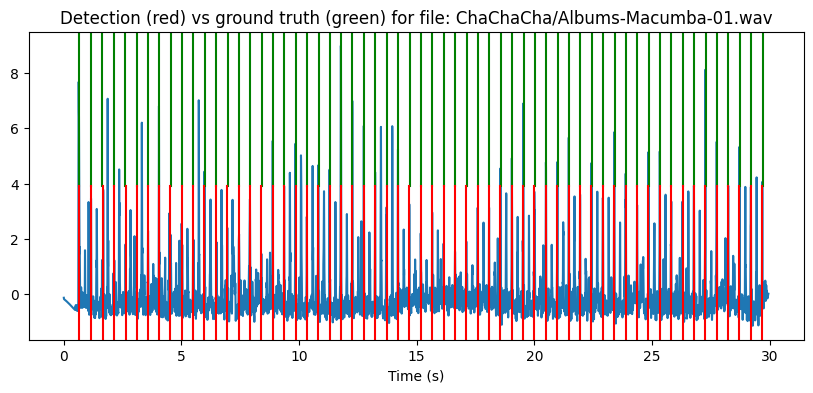

In [16]:
from evaluate import evaluate
from IPython import display as ipd

idx_max=16
track_id = test_track_ids[idx_max]
track = ballroom.track(track_id)
track_name = "/".join(track.audio_path.split("/")[-2:])
ground_truth_beats = track.beats.times
onset_strength = functions.get_onset_strength(track.audio_path, hop_time=0.004)
estimated_beats, _ = functions.beats_simple(track.audio_path, alpha=400)
functions.compare_beats(onset_strength, ground_truth_beats, estimated_beats, file_name=track_name, hop_time=0.004)


In [17]:
ipd.display(ipd.Audio(track.audio_path))

Input file: Samba/Media-106106.wav
C  FP  FN   F    Err
  0  48  49 0.000 0.000


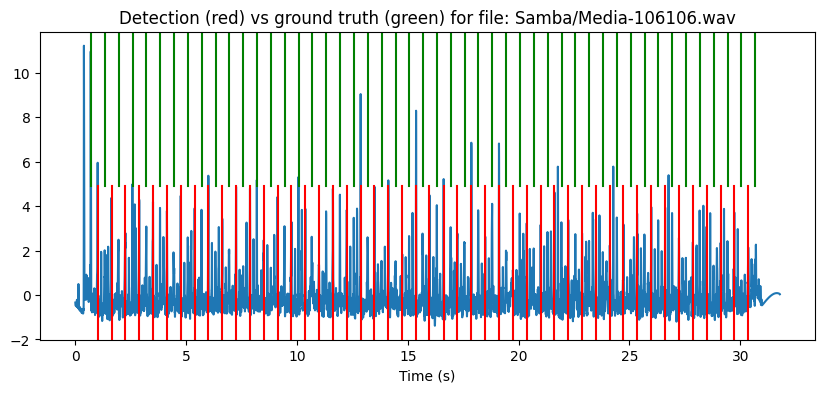

In [18]:
idx_min = 9
track_id = test_track_ids[idx_min]
track = ballroom.track(track_id)
track_name = "/".join(track.audio_path.split("/")[-2:])
ground_truth_beats = track.beats.times
onset_strength = functions.get_onset_strength(track.audio_path, hop_time=0.004)
estimated_beats, _ = functions.beats_simple(track.audio_path, alpha=400)
functions.compare_beats(onset_strength, ground_truth_beats, estimated_beats, file_name=track_name, hop_time=0.004)

In [19]:
ipd.display(ipd.Audio(track.audio_path))

In [20]:
for i, track_id in enumerate(tqdm(test_track_ids)):
    track = ballroom.track(track_id)
    split_path = track.audio_path.replace("\\", "/").split("/")
    track_name = split_path[-1]
    track_style = split_path[-2]
    metre = max(track.beats.positions)
    ground_truth_beats = track.beats.times
    ground_truth_downbeats = ground_truth_beats[track.beats.positions == 1]
    bpm = track.tempo
    _ , estimated_downbeats = functions.beats_simple(track.audio_path, alpha=alpha, sigma_t=0.9, downbeats=True)
    f1_score = mir_eval.beat.f_measure(ground_truth_downbeats, estimated_downbeats)
    test_df.loc[i, "f1_score_downbeats"] = f1_score

100%|██████████| 210/210 [01:45<00:00,  1.99it/s]


In [21]:
test_df["f1_score_downbeats"].mean()

np.float64(0.2627649180472315)

In [22]:
mean_f1_per_style_downbeats = (
    test_df.groupby("track_style")["f1_score_downbeats"]
    .mean()
    .sort_values(ascending=False)
)

mean_f1_per_style_downbeats

track_style
Rumba-International    0.396923
Samba                  0.372242
Tango                  0.327295
Quickstep              0.279598
VienneseWaltz          0.261777
Waltz                  0.231789
ChaChaCha              0.221935
Rumba-Misc             0.140266
Jive                   0.037500
Rumba-American         0.000000
Name: f1_score_downbeats, dtype: float64

In [23]:
mean_f1_per_metre_downbeats = (
    test_df.groupby("metre")["f1_score_downbeats"]
    .mean()
    .sort_values(ascending=False)
)

mean_f1_per_metre_downbeats

metre
4    0.268345
3    0.242872
Name: f1_score_downbeats, dtype: float64

Input file: ChaChaCha/Albums-Latino_Latino-01.wav
C  FP  FN   F    Err
 15   0   0 1.000 0.013


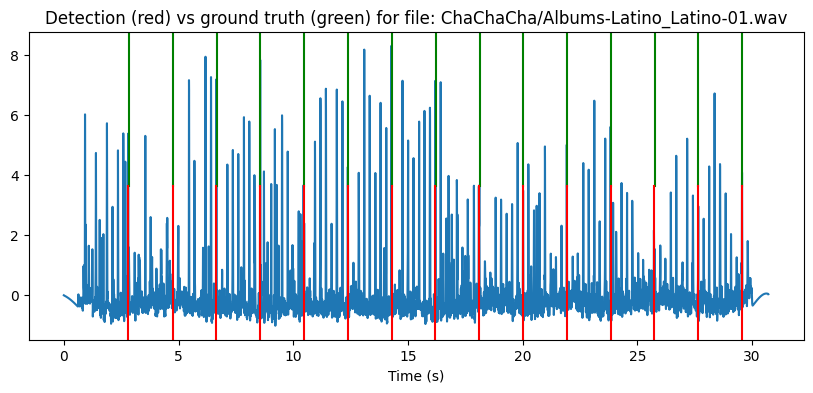

In [26]:
idx = test_df["f1_score_downbeats"].idxmax()
track_id = test_track_ids[idx]
track = ballroom.track(track_id)
track_name = "/".join(track.audio_path.split("/")[-2:])
ground_truth_beats = track.beats.times
ground_truth_downbeats = ground_truth_beats[track.beats.positions == 1]
onset_strength = functions.get_onset_strength(track.audio_path, hop_time=0.004)
_, estimated_downbeats = functions.beats_simple(track.audio_path, alpha=400)
functions.compare_beats(onset_strength, ground_truth_downbeats, estimated_downbeats, file_name=track_name, hop_time=0.004)

Input file: Rumba-International/Albums-AnaBelen_Veneo-01.wav
C  FP  FN   F    Err
  0  11  12 0.000 0.000


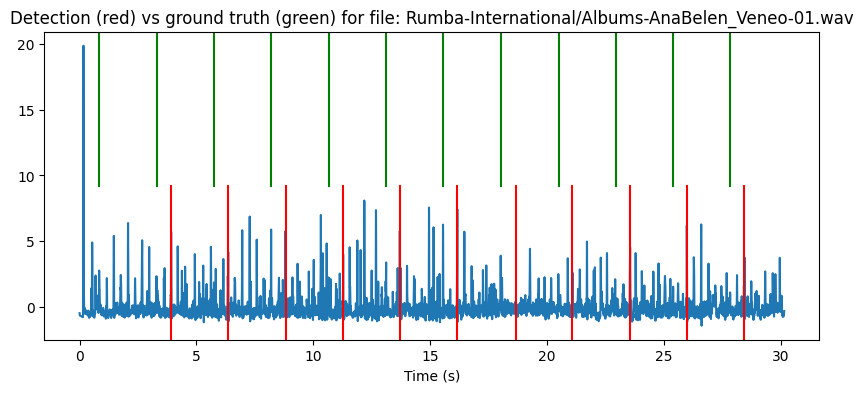

In [27]:
idx = test_df["f1_score_downbeats"].idxmin()
track_id = test_track_ids[idx]
track = ballroom.track(track_id)
track_name = "/".join(track.audio_path.split("/")[-2:])
ground_truth_beats = track.beats.times
ground_truth_downbeats = ground_truth_beats[track.beats.positions == 1]
onset_strength = functions.get_onset_strength(track.audio_path, hop_time=0.004)
_, estimated_downbeats = functions.beats_simple(track.audio_path, alpha=400)
functions.compare_beats(onset_strength, ground_truth_downbeats, estimated_downbeats, file_name=track_name, hop_time=0.004)